Anda adalah seorang Data Engineer Rumah Sakit. Data klinis pasien yang masuk ke departemen data analytics ternyata penuh masalah. Tugas Anda adalah melakukan Data Cleaning agar dataset ini bisa dipakai untuk analisis dan modelling.
 
Dataset: healthcare_patient_dataset.csv

Question 1

Outlier Detection & Handling

    Terapkan Z-Score untuk mendeteksi outlier pada bmi dan blood_sugar, sertakan visualisasi (boxplot).
    Terapkan IQR lalu lakukan winsorizing pada salah satu fitur numerik ekstrem yang kamu temukan.
    Jelaskan mengapa metode yang kamu pilih adalah yang paling tepat untuk data kesehatan tersebut.


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("healthcare_patient_dataset.csv")

df

,patient_id,age,gender,bmi,blood_pressure_sys,blood_sugar,city,smoker_status,diagnosis_risk
0,4748,29,P,NaN,137.9,111.6,Kota_073,Yes,Medium
1,1200,65,L,20.9,146.8,132.8,Kota_001,No,Low
2,5223,42,L,26.9,154.3,50.6,Kota_005,Yes,Medium
3,4548,44,L,NaN,116.5,85.9,Kota_057,No,Low
4,1863,57,P,28.3,100.6,160.0,Kota_064,No,High
...,...,...,...,...,...,...,...,...,...
5495,3773,33,L,37.2,115.7,115.6,Kota_079,Yes,Medium
5496,5192,44,P,33.8,126.7,475.0,Kota_082,No,Low
5497,5227,39,L,24.3,99.8,146.6,Kota_058,No,Medium
5498,5391,35,P,25.1,116.2,86.6,Kota_111,No,Low


In [4]:
std_bmi = df['bmi'].std()
mean_bmi = df['bmi'].mean()
df['zscore_bmi'] = (df['bmi'] - mean_bmi) / std_bmi
df['zscore_outlier_bmi'] = (df['zscore_bmi'] > 3) | (df['zscore_bmi'] < -3)


In [5]:
df['zscore_bmi'].describe()

count    5.233000e+03
mean    -1.181296e-16
std      1.000000e+00
min     -1.762018e+00
25%     -5.152765e-01
50%     -1.042628e-01
75%      3.204514e-01
max      6.595261e+00
Name: zscore_bmi, dtype: float64

In [6]:
df[df['zscore_outlier_bmi']]

,patient_id,age,gender,bmi,blood_pressure_sys,blood_sugar,city,smoker_status,diagnosis_risk,zscore_bmi,zscore_outlier_bmi
65,927,37,L,70.0,117.3,82.6,Kota_004,No,Low,5.910238,True
111,697,50,P,60.0,110.8,119.3,Kota_017,No,Low,4.540193,True
166,1860,49,L,65.0,122.2,106.1,Kota_098,No,Medium,5.225215,True
203,4759,35,L,60.0,91.4,137.1,Kota_043,Yes,Medium,4.540193,True
239,1050,66,L,60.0,128.4,91.5,Kota_055,No,Low,4.540193,True
...,...,...,...,...,...,...,...,...,...,...,...
4951,3720,43,P,75.0,106.9,87.9,Kota_046,No,Low,6.595261,True
4989,4172,43,L,65.0,96.2,68.6,Kota_064,No,Low,5.225215,True
5002,3852,52,P,65.0,128.5,118.9,Kota_096,Yes,Low,5.225215,True
5142,972,35,P,75.0,123.6,122.8,Kota_100,No,High,6.595261,True


In [7]:
df['zscore_outlier_bmi'].sum()

np.int64(110)

In [8]:
std_blood_sugar = df['blood_sugar'].std()
mean_blood_sugar = df['blood_sugar'].mean()
df['zscore_blood_sugar'] = (df['blood_sugar'] - mean_blood_sugar) / std_blood_sugar
df['zscore_outlier_blood_sugar'] = (df['zscore_blood_sugar'] > 3) | (df['zscore_blood_sugar'] < -3)

In [9]:
df['zscore_outlier_blood_sugar'].sum()

np.int64(132)

In [10]:
df[df['zscore_outlier_blood_sugar']]

,patient_id,age,gender,bmi,blood_pressure_sys,blood_sugar,city,smoker_status,diagnosis_risk,zscore_bmi,zscore_outlier_bmi,zscore_blood_sugar,zscore_outlier_blood_sugar
34,1965,53,L,19.6,112.8,500.0,Kota_109,No,Medium,-0.994793,False,4.548218,True
40,3241,45,P,23.7,111.9,475.0,Kota_037,No,Low,-0.433074,False,4.251427,True
140,4432,18,P,16.6,118.6,475.0,Kota_054,No,Low,-1.405806,False,4.251427,True
220,419,63,L,26.2,133.8,450.0,Kota_092,Yes,Medium,-0.090562,False,3.954635,True
230,4891,33,L,25.8,NaN,475.0,Kota_036,Yes,Low,-0.145364,False,4.251427,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5348,1530,28,P,17.9,111.2,999.0,Kota_010,No,Low,-1.227700,False,10.472173,True
5357,1598,76,L,26.1,NaN,475.0,Kota_059,No,Medium,-0.104263,False,4.251427,True
5418,338,40,L,31.0,121.8,999.0,Kota_085,No,Low,0.567060,False,10.472173,True
5493,467,54,L,25.3,136.2,450.0,Kota_055,No,Medium,-0.213866,False,3.954635,True


In [11]:
df['zscore_blood_sugar'].describe()

count    5.500000e+03
mean     4.263256e-17
std      1.000000e+00
min     -7.940258e-01
25%     -4.438120e-01
50%     -1.885715e-01
75%      1.331503e-01
max      1.047217e+01
Name: zscore_blood_sugar, dtype: float64

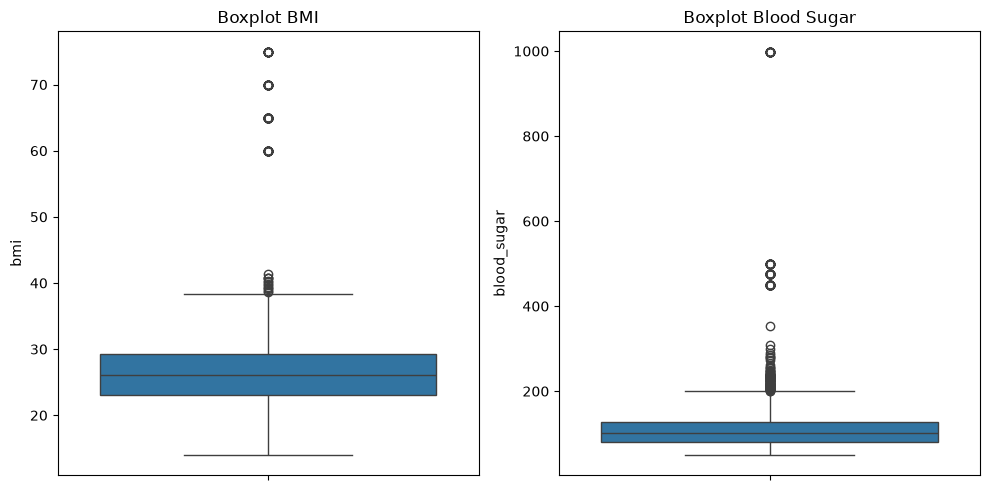

In [12]:
import seaborn as sns 
import matplotlib.pyplot as plt 

fig, axes = plt.subplots(1,2, figsize=(10,5))
sns.boxplot(y=df['bmi'], ax=axes[0])
axes[0].set_title('Boxplot BMI')

sns.boxplot(y=df['blood_sugar'], ax=axes[1])
axes[1].set_title('Boxplot Blood Sugar')

plt.tight_layout()
plt.show()

In [13]:
q1, q3 = df['blood_sugar'].quantile([0.25,0.75])
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q1 + 1.5 * iqr
df['blood_sugar_wins'] = df['blood_sugar'].clip(lower=batas_bawah, upper=batas_atas)

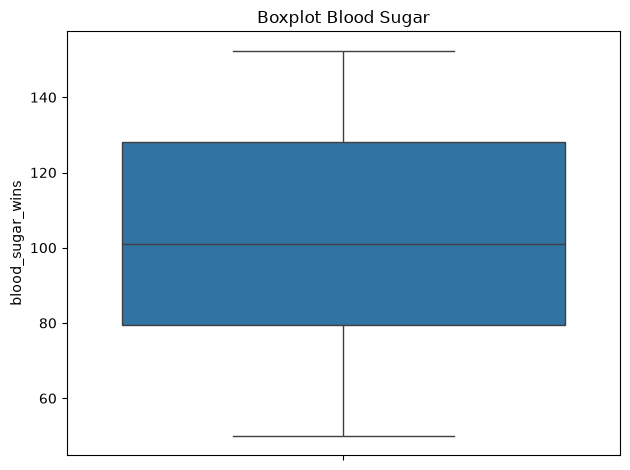

In [14]:
import seaborn as sns 
import matplotlib.pyplot as plt 

sns.boxplot(y=df['blood_sugar_wins']).set_title('Boxplot Blood Sugar')


plt.tight_layout()
plt.show()

In [15]:
df[['blood_sugar','blood_sugar_wins']]

,blood_sugar,blood_sugar_wins
0,111.6,111.6
1,132.8,132.8
2,50.6,50.6
3,85.9,85.9
4,160.0,152.4
...,...,...
5495,115.6,115.6
5496,475.0,152.4
5497,146.6,146.6
5498,86.6,86.6


In [16]:
df[['blood_sugar','blood_sugar_wins']].describe()

,blood_sugar,blood_sugar_wins
count,5500.000000,5500.000000
mean,116.884182,104.015745
std,84.234266,30.514971
min,50.000000,50.000000
25%,79.500000,79.500000
50%,101.000000,101.000000
75%,128.100000,128.100000
max,999.000000,152.400000


IQR berbasis kuartil (median) sehingga tidak terpengaruh oleh nilai ekstrem. Yang terpengaruh nilai ekstrem adalah Mean dan Std, itu sebabnya Z score kurang cocok

Question 2

Handling Missing Values

    Imputasi blood_pressure_sys menggunakan median dan tampilkan perbandingan statistika sebelum–sesudah.
    Imputasi smoker_status menggunakan mode, dan tunjukkan jumlah missing berkurang.
    Jelaskan dampak kesalahan imputasi pada analisis kesehatan.

 


In [17]:
df['blood_pressure_sys'].isna().sum()

np.int64(550)

In [18]:
df['blood_pressure_sys'].describe()
median_blood_pressure_sys = df['blood_pressure_sys'].median()
df['blood_pressure_sys_after'] = df['blood_pressure_sys'].fillna(median_blood_pressure_sys)

df[['blood_pressure_sys','blood_pressure_sys_after']].describe()


,blood_pressure_sys,blood_pressure_sys_after
count,4950.000000,5500.000000
mean,122.188323,122.184491
std,15.981256,15.161002
min,80.000000,80.000000
25%,111.300000,112.600000
50%,122.150000,122.150000
75%,133.300000,131.825000
max,193.700000,193.700000


In [19]:
nan_smoker_status_before = df['smoker_status'].isna().sum()
nan_smoker_status_before

np.int64(440)

In [20]:
mode_smoker_status = df['smoker_status'].mode()[0]
df['smoker_status'] = df['smoker_status'].fillna(mode_smoker_status)

df['smoker_status'].isna().sum()

np.int64(0)

dampak kesalahan imputasi pada analisis kesehatan adalah 
1. variasi data mengecil : contohnya pada saat menginput nilai nan pada data blood pressure sys membuat std turun dari 15.98 ke 15.16. data terkesan lebih seragam dari kenyataan padahal pasien bisa saja punya tekanan darat sangat tinggi ato sangat rendah

2. bias pada kategori : contohnya saat data kosong pada smoker status diinput misalnya "No" maka pasien tersebut dianggap bukan perokok . padahal bisa saja pasien tersebut perokok

3. data terlihat lengkap padahal "buatan"

4. analisis yang dilakukan menggunakan data yg bias bisa salah menilai resiko pasien

Question 3

Encoding Categorical Data

    Terapkan Ordinal Encoding pada diagnosis_risk (Low < Medium < High).
    Terapkan Binary / Frequency Encoding pada city (high-cardinality).
    Jelaskan konsekuensi pemilihan encoding yang salah pada dataset medis.

 


In [21]:
urutan = {'Low':0, 'Medium': 1, 'High':2}
df['diagnosis_risk_encoded'] = df['diagnosis_risk'].map(urutan)



In [22]:
freq = df['city'].value_counts()

df['city_freq'] = df['city'].map(freq)

df

,patient_id,age,gender,bmi,blood_pressure_sys,blood_sugar,city,smoker_status,diagnosis_risk,zscore_bmi,zscore_outlier_bmi,zscore_blood_sugar,zscore_outlier_blood_sugar,blood_sugar_wins,blood_pressure_sys_after,diagnosis_risk_encoded,city_freq
0,4748,29,P,NaN,137.9,111.6,Kota_073,Yes,Medium,NaN,False,-0.062732,False,111.6,137.9,1,46
1,1200,65,L,20.9,146.8,132.8,Kota_001,No,Low,-0.816687,False,0.188947,False,132.8,146.8,0,73
2,5223,42,L,26.9,154.3,50.6,Kota_005,Yes,Medium,0.005341,False,-0.786903,False,50.6,154.3,1,38
3,4548,44,L,NaN,116.5,85.9,Kota_057,No,Low,NaN,False,-0.367833,False,85.9,116.5,0,66
4,1863,57,P,28.3,100.6,160.0,Kota_064,No,High,0.197147,False,0.511856,False,152.4,100.6,2,231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5495,3773,33,L,37.2,115.7,115.6,Kota_079,Yes,Medium,1.416488,False,-0.015245,False,115.6,115.7,1,131
5496,5192,44,P,33.8,126.7,475.0,Kota_082,No,Low,0.950673,False,4.251427,True,152.4,126.7,0,92
5497,5227,39,L,24.3,99.8,146.6,Kota_058,No,Medium,-0.350871,False,0.352776,False,146.6,99.8,1,33
5498,5391,35,P,25.1,116.2,86.6,Kota_111,No,Low,-0.241267,False,-0.359523,False,86.6,116.2,0,30


konsekuensi jika salah pilih encoding pada dataset medis:

1. bisa memberikan kesimpulan yg menyesatkan
2. model salah menilai resiko pasien (false negative)
3. hasil sulit diaudit

Question 4.

Scaling & Normalization

    Terapkan Min-Max Scaling pada fitur age, lalu tampilkan distribusi hasil scaling.
    Terapkan Robust Scaling pada bmi (karena outlier), bandingkan hasilnya.
    Jelaskan mengapa scaling penting dalam model prediksi risiko pasien.


 



In [23]:
min_age = df['age'].min()
max_age = df['age'].max()

df['age_minmax'] = (df['age'] - min_age) / (max_age - min_age)

df[['age','age_minmax']]

,age,age_minmax
0,29,0.152778
1,65,0.652778
2,42,0.333333
3,44,0.361111
4,57,0.541667
...,...,...
5495,33,0.208333
5496,44,0.361111
5497,39,0.291667
5498,35,0.236111


In [24]:
df[['age','age_minmax']].describe()

,age,age_minmax
count,5500.000000,5500.000000
mean,45.229455,0.378187
std,14.417125,0.200238
min,18.000000,0.000000
25%,35.000000,0.236111
50%,45.000000,0.375000
75%,55.000000,0.513889
max,90.000000,1.000000


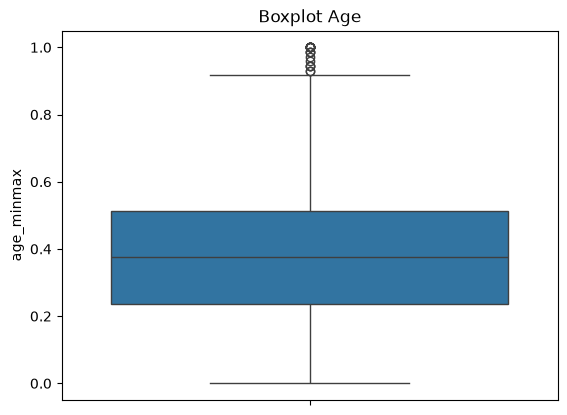

In [25]:
sns.boxplot(y=df['age_minmax']).set_title('Boxplot Age')
plt.show()

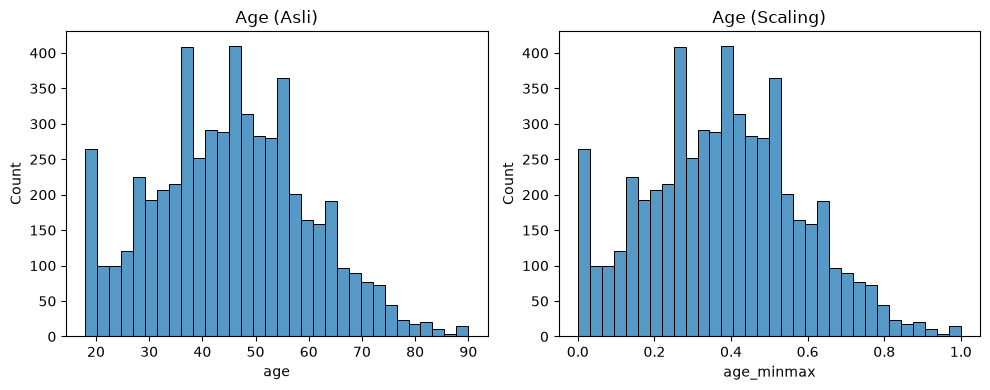

In [26]:
fig, axes = plt.subplots(1,2,figsize=(10,4))

sns.histplot(df['age'], ax=axes[0]).set_title('Age (Asli)')
sns.histplot(df['age_minmax'], ax=axes[1]).set_title('Age (Scaling)')

plt.tight_layout()
plt.show()


In [27]:
min_bmi = df['bmi'].min()
max_bmi = df['bmi'].max()

df['bmi_minmax'] = (df['bmi'] - min_bmi) / (max_bmi - min_bmi)

In [28]:
median_bmi = df['bmi'].median()
q1_bmi, q3_bmi = df['bmi'].quantile([0.25,0.75])
iqr_bmi = q3_bmi - q1_bmi 

df['bmi_robust'] = (df['bmi'] - median_bmi ) / iqr_bmi

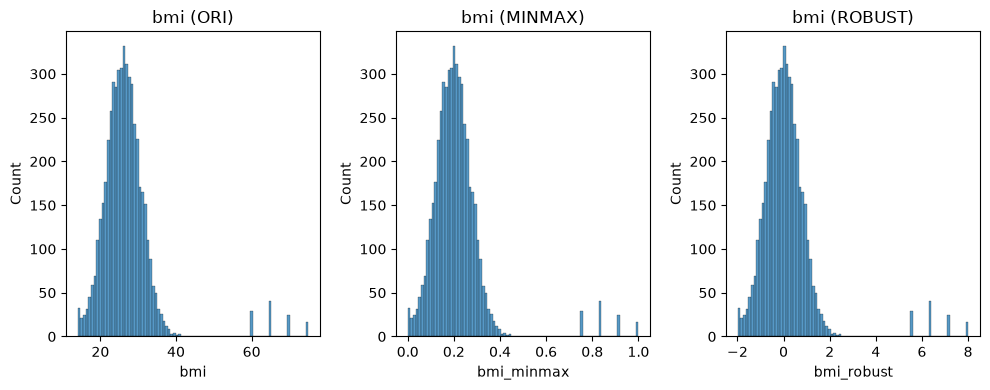

In [29]:
fig, axes = plt.subplots(1,3,figsize=(10,4))

sns.histplot(df['bmi'], ax = axes[0]).set_title('bmi (ORI)')
sns.histplot(df['bmi_minmax'], ax = axes[1]).set_title('bmi (MINMAX)')
sns.histplot(df['bmi_robust'], ax = axes[2]).set_title('bmi (ROBUST)')

plt.tight_layout()
plt.show()

In [30]:
df[['bmi','bmi_minmax','bmi_robust']].describe()

,bmi,bmi_minmax,bmi_robust
count,5233.000000,5233.000000,5233.000000
mean,26.861017,0.210836,0.124757
std,7.299026,0.119656,1.196562
min,14.000000,0.000000,-1.983607
25%,23.100000,0.149180,-0.491803
50%,26.100000,0.198361,0.000000
75%,29.200000,0.249180,0.508197
max,75.000000,1.000000,8.016393


kenapa ini penting pada prediksi resiko pasien:
1. fitur yang memiliki angka besar tidak mendominasi 
2. training lebih cepat dan stabil
3. bobot lebih adil dan mudah dibandingkan
4. outlier tidak merusak skala fitur lain

jika tidak melakukan scaling pada data medis maka model bisa salah menilai resiko pasien

Question 5

Distribution Transformation

    Lakukan Log Transform pada blood_sugar dan tunjukkan perubahan skewness.
    Lakukan Yeo-Johnson Transform pada bmi dan tampilkan histogram.
    Jelaskan kapan transformasi tidak boleh digunakan pada data klinis.

 


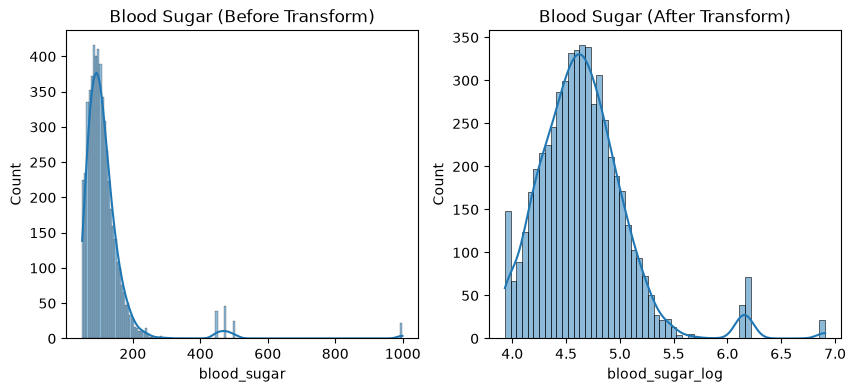

In [31]:
import numpy as np

df['blood_sugar_log'] = np.log1p(df['blood_sugar'])

fig, axes = plt.subplots(1,2,figsize=(10,4))

sns.histplot(df['blood_sugar'], kde=True,ax=axes[0]).set_title('Blood Sugar (Before Transform)')
sns.histplot(df['blood_sugar_log'], kde=True,ax=axes[1]).set_title('Blood Sugar (After Transform)')


plt.show()

In [32]:
print(f'Before log : {df['blood_sugar'].skew()}')
print(f'After log : {df['blood_sugar_log'].skew()}')

Before log : 6.120424611665099
After log : 1.4444781941709302


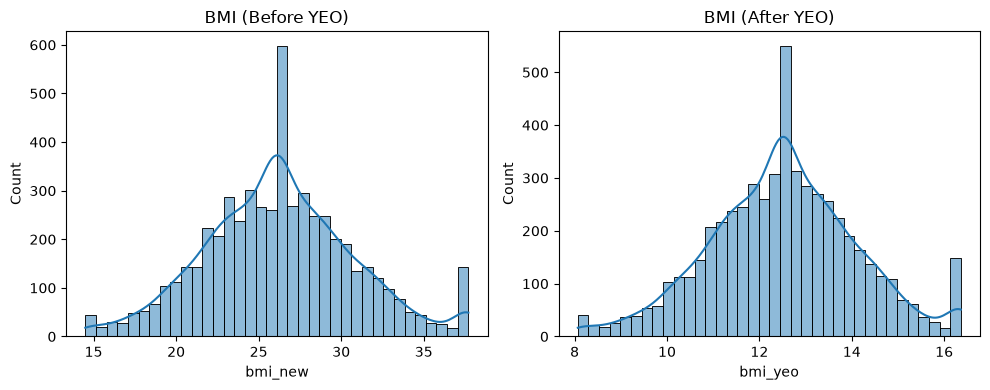

In [33]:
from scipy import stats

df['bmi_new'] = df['bmi'].fillna(df['bmi'].median())

q1, q3 = df['bmi_new'].quantile([0.25,0.75])
iqr = q3 - q1 
low, high = q1 - 1.5*iqr , q3 + 1.5 *iqr 
df['bmi_new'] = df['bmi_new'].clip(lower=low, upper=high)

df['bmi_yeo'], _ = stats.yeojohnson(df['bmi_new'])

fig, axes = plt.subplots(1,2, figsize=(10,4))

sns.histplot(df['bmi_new'], ax=axes[0],kde=True).set_title('BMI (Before YEO)')
sns.histplot(df['bmi_yeo'], ax=axes[1],kde=True).set_title('BMI (After YEO)')
plt.tight_layout()
plt.show()


In [34]:
print(f'Before Yeo : {df['bmi_new'].skew()}')
print(f'After Yeo : {df['bmi_yeo'].skew()}')

Before Yeo : 0.17332374268345935
After Yeo : 0.004276568944626129


Transformasi data sebaiknya tidak dipakai pada data klinis ketika :

1. Nilai aslinya punya makna klinis langsung. Ambang seperti BMI ≥ 30 (obesitas), tekanan darah ≥ 140/90, atau HbA1c ≥ 6,5% dipakai dokter dalam skala asli. Setelah ditransformasi, angkanya (misalnya BMI jadi 12,8) tidak bisa dibaca klinisi dan tidak bisa dibandingkan dengan ambang standar.

2. Outlier adalah kasus nyata, bukan error. Nilai ekstrem seperti kreatinin sangat tinggi atau gula darah 600 bisa jadi pasien kritis. Clip atau transformasi yang "menjinakkan" outlier justru menyembunyikan kasus paling penting. Outlier hanya boleh dibuang atau di-clip kalau terbukti salah input (misalnya BMI 75 pada data yang jelas tidak realistis, dan itu pun harus diverifikasi ke sumber data).

3. Modelnya tidak butuh distribusi normal. Pohon keputusan, random forest, dan gradient boosting tidak sensitif terhadap skewness, jadi transformasi hanya menambah kerumitan tanpa manfaat. Transformasi berguna terutama untuk regresi linear/logistik, uji parametrik, atau model berbasis jarak.

4. Hasil harus diinterpretasikan dalam satuan asli. Koefisien regresi pada variabel yang di-Yeo-Johnson sulit dijelaskan ("naik 1 unit BMI-YEO" tidak bermakna bagi pasien). Kalau interpretabilitas penting untuk publikasi atau keputusan klinis, pertimbangkan alternatif seperti binning berdasarkan kategori klinis atau model yang robust terhadap skewness.

5. Distribusinya memang tidak normal secara biologis. Beberapa biomarker (misalnya trigliserida, CRP) secara alami miring ke kanan. Itu karakteristik data, bukan masalah yang harus dikoreksi, kecuali analisisnya memang mensyaratkan normalitas.

6. Risiko data leakage. Parameter transformasi (lambda, median, batas IQR) harus dihitung dari data latih saja, lalu diterapkan ke data uji. Menghitungnya dari seluruh data membuat evaluasi model terlalu optimis.

Question 6

Imbalance Data

    Tampilkan class distribution diagnosis_risk sebelum & sesudah balancing.
    Terapkan SMOTE untuk menyeimbangkan kelas minoritas.
    Jelaskan risiko oversampling yang berlebihan pada data medis.




In [36]:
print(df['diagnosis_risk'].value_counts())
print(df['diagnosis_risk'].value_counts(normalize=True))

diagnosis_risk
Low       2956
Medium    1983
High       561
Name: count, dtype: int64
diagnosis_risk
Low       0.537455
Medium    0.360545
High      0.102000
Name: proportion, dtype: float64


In [38]:
from imblearn.over_sampling import SMOTE 

X = df[['age','bmi_new','blood_pressure_sys_after','blood_sugar_wins']]
y = df['diagnosis_risk']

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X,y)

print(y_res.value_counts())
print(y_res.value_counts(normalize=True))


diagnosis_risk
Medium    2956
Low       2956
High      2956
Name: count, dtype: int64
diagnosis_risk
Medium    0.333333
Low       0.333333
High      0.333333
Name: proportion, dtype: float64


Before : Low 53,7%, Medium 36,1%, High 10,2% (Imbalance)
After  : Masing-masing 33,3% (Balance)

Resiko : sebagian besar sintetis sehingga rawan overfitting, pasien sintetis yang tidak realistis dan data leakage jika SMOTE dilakukan sebelum split train test